In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
# import util
import scipy as sp
import matplotlib.pyplot as plt

import sys
sys.path.insert(1, '../')
import util
from util import stationary

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import tqdm

# Defining functions

In [2]:
def update_equation(D,A=None,pc=None,pr=None,order='ST'):
    """ 
    update_equation updates the probability(ies) to be degraded, D, by one time step, 
    given the interaction matrix A, collapse rate pc and recovery rate pr

    Parameters
    ---
    D : numpy.array
        The initial array of degraded probabilities
    A : numpy.array
        The interaction matrix (i.e. adjacency matrix), must be of shape (len(D), len(D)). 
        No self loops, i.e. all diagonal elements should be 0.
        Default is np.zeros([len(D)]*2) i.e. the empty graph, such that all Markov chains are disconnected.
    pc : numpy.array or something broadcastable
        The array/list/collection of collapse rates. Must be in [0,1]. 
        If none supplied, default is 1/2 for all Markov chains
    pr : numpy.array or something broadcastable
        The array/list/collection of collapse rates. Must be in [0,1]
        If none supplied default is tr = 10tc where tr is the recovery time and 
        tc the collapse time with pc=1/(tc+1)
    order : str
        The order of the interaction matrix, 
        if 'ST' then the interaction matrix is indexed as A[source, target]
        if 'TS' then the interaction matrix is indexed as A[target, source]
        Default is 'ST'
        
    Returns
    ---
    D_out : numpy.array

    Examples
    ---
    For an initial vector of zeros, regardless of the interaction matrix, D_out will always be pc
    >>> update_equation(np.zeros(2), A = np.array( [[0, -2], [4, 0]] ), pc = np.array([0.2, 0.9]), order='ST')
    array([0.2, 0.9]) 
    
    For an initial vector of ones, regardless of the interaction matrix, D_out will always be pr
    >>> update_equation(np.ones(2), A = np.array( [[0, -2], [4, 0]] ), pc = np.array([0.2, 0.9]), pr = np.array([0.5, 0.5]), order='ST')
    array([0.5, 0.5])

    For non-trivial initial D:
    >>> update_equation(np.array([0, 1]), A = np.array( [[0, -2], [4, 0]] ), pc = np.array([0.2, 0.9]), 
        >>> pr = np.array([0.5, 0.5]), order='ST')
    array([1, 0.5])
    >>> update_equation_quick(np.array([0.5, 0.5]), np.array( [[0, 1], [1, 0]] ), np.array([0.2, 0.45]), np.array([0.6, 0.3]))
    array([0.35  , 0.6875])
    """
    if A is None:
        A = np.zeros([len(D)]*2)
    elif order == 'ST':
        A = A.transpose()
    if pc is None:
        pc = np.ones(len(D))/2
    if pr is None:
        pr = 1/(10/pc - 9)

    ### Decomposing interaction matrix as A = A_pos + A_neg, 
        ### where A_pos contains all positive elements of A, while A_neg contains all negatives
    A_pos = np.maximum(A,0)
    A_neg = np.maximum(-A,0)
    d_pos = np.dot(A_pos,D)
    d_neg = np.dot(A_neg,D)

    return (1+d_pos)*pc*(1-D)/(1+d_neg) + (1-pr)*D

def update_equation_quick(D,A,pc,pr):
    """ 
    update_equation_quick updates the probability(ies) to be degraded, D, by one time step, 
    given the interaction matrix A, collapse rate pc and recovery rate pr. 
    Quicker version to go into wrappers and other fns

    Parameters
    ---
    D : numpy.array
        The initial array of degraded probabilities
    A : numpy.array
        The interaction matrix (i.e. adjacency matrix), must be of shape (len(D), len(D)). 
        No self loops, i.e. all diagonal elements should be 0. Must be indexed as A[target,source]
    pc : numpy.array or something broadcastable
        The array/list/collection of collapse rates. Must be in [0,1]. 
    pr : numpy.array or something broadcastable
        The array/list/collection of collapse rates. Must be in [0,1]
        
    Returns
    ---
    D_out : numpy.array

    Examples
    ---
    For an initial vector of zeros, regardless of the interaction matrix, D_out will always be pc
    >>> update_equation(np.zeros(2), np.array( [[0, 4], [-2, 0]] ),np.array([0.2, 0.9]))
    np.array([0.2, 0.9]) 

    For numnerical examples see update_equation
    """
    return (1+np.dot(np.maximum(A,0),D))*pc*(1-D)/(1+np.dot(np.maximum(-A,0),D)) + (1-pr)*D

def temp_response(T,T_lim,beta):
    """ 
    Returns the response in collapse rate to a temperature T, 
    for a tipping element with threshold T_lim and temperature sensitivity (i.e. logistic parameter) beta
    
    Parameters
    ---
    T : numpy.array or float
        Temperature(s)
    T_lim : numpy.array or float
        Tipping/critical threshold(s)
    beta : numpy.array or something broadcastable
        Temperature sensitivity(ies) (i.e. logistic parameter)

    Returns
    ---
    out : numpy.array
    """
    return 1/(1+np.exp(beta*(T_lim-T)))

def evolve(D_init, A, no_time_steps, 
           order_ST=True, 
           pc = None, tau_c = None, 
           T = None, beta = None, T_lim = None,
           pr = None, tau_r = None,
           ):
    """ 
    Wrapper to evolve system up to and including t = no_time_steps, 
    with an initial value of D_init at time t=0. 

    Parameters (required)
    ---
    D_init : numpy.array
        The initial array of degraded probabilities at time step 0
    A : numpy.array
        The interaction matrix (i.e. adjacency matrix), must be of shape (len(D_init), len(D_init)). 
        No self loops, i.e. all diagonal elements should be 0. 
    no_time_steps : int
        The number of time steps to simulate over, 
        i.e. the number of times the update equation is successively applied. 
        Must be >= 1
    
    Parameters (optional):
    order_ST : Bool
        The indexing order of the adjacent matrix. 
        If True, then the adjacency matrix will be read with an index-order that gives A[source, target].
        Otherwise the order will be assumed as A[target, source]
        Default True.
    pc : numpy.array or something broadcastable
        The array/list/collection of collapse rates (without interactions). 
        Will supercede any calls to tau_c or T
        Must be in [0,1]. 
    tau_c :  numpy.array or something broadcastable
        The array/list/collection of collapse time scales. 
    T : array-like or float
        The global temperature(s) at which to evaluate. 
        Must be of length >= no_time_steps. Must have beta and T_lim supplied as well if not None
    beta : array-like or float
        Temperature sensitivities (i.e. logistic parameters) for individual tipping points.
        If array-like must be of length len(D_init). 
    T_lim : array-like or float
        Critical temperature thresholds for individual tipping points.
        If array-like must be of length len(D_init)
    pr : numpy.array or something broadcastable
        The array/list/collection of collapse rates. Will supercede tau_r
    tau_r : numpy.array or something broadcastable
        The array/list/collection of collapse time scales
    
        
    Returns
    ---
    D_out : numpy.array
        The output will be a (len(D_init), no_time_steps+1)-shaped array where the D_out[:,0] = D_init
    Examples
    ---
    """
    ## Initialising D_out
    D_out = np.zeros((len(D_init), no_time_steps))
    D_out[:,0] = D_init
    
    ## Changing pc if needed
    if pc is None:
        if tau_c is None:
            raise ValueError("No collapse time scales given")
            pc = np.ones(len(D_init))/2 ## if nothing is supplied pc will be set to 1/2
        elif (T is None) or (beta is None) or (T_lim is None):
            # if any of T,T_lim,beta are None, then pc = 1/(tau_c+1)
            pc = np.ones((len(D_init), no_time_steps))/(tau_c.reshape(len(D_init),1)+1)
            # print('Non-critical error: at least one of T, T_lim or beta has not been provided.')
        else:
            pc = np.ones((len(D_init), no_time_steps))
            pc /= (tau_c.reshape(len(D_init),1)+1)
            for t in range(no_time_steps):
                pc[:,t] *= temp_response(T[t], T_lim, beta)
    if np.any(pc>1) or np.any(pc<0):
        raise ValueError("Collapse probability pc not in [0,1]")
    ## Changing pr if needed
    if pr is None:
        if tau_r is None:  
            raise ValueError("No recovery time scales given")
        else:
            pr = 1/(tau_r+1)
    if np.any(pr>1) or np.any(pr<0):
        raise ValueError("Recovery probability pr not in [0,1]")
    # print(pr.shape)
    if order_ST:
        A = A.transpose()

    for t in range(1,no_time_steps):
        D_out[:,t] = update_equation_quick(D_out[:,t-1],A,pc[:,t-1],pr)

    return D_out

In [10]:
def stat_dist_theory_res(D,*data):
    A,q_c,q_r = data
    x_pos = np.dot(np.transpose(np.where(A>=0,A,0)),D)
    x_neg = np.dot(np.transpose(np.where(A<0,-A,0)),D)
    # out = np.zeros(len(D))
    # for i in range(len(D)):
    #     out[i] = D[i] - (1+x_pos[i])*q_c[i]/((1+x_pos)*q_c[i] + (1+x_neg)*q_r[i])
    out = D - (1+x_pos)*q_c/((1+x_pos)*q_c + (1+x_neg)*q_r)
    return out

def stat_dist_theory(A,q_c,q_r,T,T_lim,beta):
    return sp.optimize.fsolve(stat_dist_theory_res, np.ones(9), args=(A,temp_response(T, T_lim,beta)*q_c,q_r))

# Testing

## Reading individual TE data

In [5]:
folder = '../../Data/'
df_TEs = pd.read_excel(folder+'TEsummary.xlsx',header=[0],index_col=0)

df_TEs.head()

,Tipping element,Collapse (years),Recovery (years),Threshold (°C) – Min.,Threshold (°C) – Est.,Threshold (°C) – Max.,Beta (1/°C),Max Impact (°C) – Global,Comments
TE,,,,,,,,,
AMAZ,Amazon rainforest dieback,100,1000,2.0,3.5,6.0,4.604503,0.20,"Max impact for a total die back is 0.2C, while..."
AMOC,Atlantic meridional ocean circulation,50,500,1.4,4.0,8.0,2.656444,-0.50,NaN
ASI,Arctic winter sea ice,20,200,4.5,6.3,8.7,3.837086,0.60,NaN
ENSO,El Nino Southern Oscillation,100,1000,3.0,4.5,6.0,4.604503,0.00,From Armstrong McKay et al no estimate for max...
GIS,Greenland ice sheet,10000,100000,0.8,1.5,3.0,9.866793,0.13,NaN


## Reading generated interaction matrices

In [6]:
folder = "../Data/Interaction matrices/"
no_samples = 500
A = [np.loadtxt(folder+'A_'+str(r)+'.csv') for r in range(no_samples)]

FileNotFoundError: ../Data/Interaction matrices/A_0.csv not found.

In [ ]:
D = np.zeros(9)
T = +1.5
D_out = update_equation_quick(D,A[0],
                              temp_response(T,df_TEs['Threshold (°C) – Est.'].to_numpy(), 
                                            df_TEs['Beta (1/°C)']).to_numpy()/ (df_TEs['Collapse (years)'].to_numpy() + 1),
                              1/(df_TEs['Recovery (years)'].to_numpy()+1))

## Reading extended ssps

In [27]:
df = pd.read_excel('../../Data/extendedSSPs.xlsx')
scenarios = df['scenario'].unique()

dfs = {s: df[df['scenario']==s].set_index('quantile').iloc[:,9:].transpose() for s in scenarios}
years = np.arange(1850, 2351)
no_years = len(years)

In [4]:
scenarios

array(['ssp119', 'ssp126', 'ssp245', 'ssp370', 'ssp534-over', 'ssp585'],
      dtype=object)

In [30]:
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *=q_c

In [12]:
scenarios = ['1a','1b','2a','2b']
temps = {}
temps['1a'] = np.concatenate((np.arange(0,2.01,step=0.02),
                         np.ones(200)*2,
                         np.arange(0,2,step=0.02)[::-1]))
temps['1b'] = np.concatenate((np.arange(0,2.01,step=0.02),
                         np.ones(1200)*2))
# temps['1c'] = np.concatenate((np.arange(0,2.01,step=0.02),
#                          np.ones(1200)*2,
#                          np.arange(0,2,step=0.02)[::-1]))

temps['2a'] = np.concatenate((np.arange(0,4.01,step=0.02),
                         np.ones(200)*4,
                         np.arange(0,4,step=0.02)[::-1]))
temps['2b'] = np.concatenate((np.arange(0,4.01,step=0.02),
                         np.ones(1200)*4))

In [14]:
years = np.arange(1850, 2351) 
# D_out = evolve(np.zeros(9), A[0], len(years),
#                tau_c = df_TEs['Collapse (years)'].to_numpy(),
#                tau_r = df_TEs['Recovery (years)'].to_numpy(),
#                T = dfs['ssp119']['mean'].to_numpy(),
#                beta=df_TEs['Beta (1/°C)'].to_numpy(),
#                T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy())
s='1a'
D_out = util.evolve(np.zeros(9), A[0], len(temps[s]),
               tau_c = df_TEs['Collapse (years)'].to_numpy(),
               tau_r = df_TEs['Recovery (years)'].to_numpy(),
               T = temps[s],
               beta=df_TEs['Beta (1/°C)'].to_numpy(),
               T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy())

## simulating with extended ssps

In [6]:
import numpy as np
import pandas as pd
import io
import scipy as sp

import sys
sys.path.insert(1, '/home/jbara/Code/NMaCh-TP/Code/')
from util import dynamics
import tqdm

# Reading data about individual tipping elements:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0)
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
p_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Reading extended SSP temperatures
years = np.arange(1850, 2351) 
no_years = len(years)
df = pd.read_excel('../../Data/extendedSSPs.xlsx')
scenarios = df['scenario'].unique()
dfs = {s: df[df['scenario']==s].set_index('quantile').iloc[:,9:].transpose() for s in scenarios}

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *= q_c
for t in range(no_years):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= dynamics.temp_response(dfs[s]['mean'].to_numpy()[t], T_lim, betas)

In [7]:
# Simulating dynamics for TEs with interactions
D = np.zeros((len(scenarios),len_sample,len(df_TEs),no_years))
for r in tqdm.tqdm(range(len_sample)):
    for j in range(len(scenarios)):
        for t in range(1,no_years):
            D[j,r,:,t] = dynamics.environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r)

# Simulating dynamics for TEs without interactions
D_noint = np.zeros((len(scenarios),len(df_TEs),no_years))
for t in tqdm.tqdm(range(1,no_years)):
    for j in range(len(scenarios)):
        D_noint[j,:,t] = dynamics.environmental_update(D_noint[j,:,t-1],np.zeros((len(df_TEs),len(df_TEs))),pc=p_c[j,t,:],pr=p_r)

100%|██████████████████████████████████████| 500/500 [00:00<00:00, 20232.43it/s]


## plotting

In [ ]:
fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--', (2,(10,3)) ,(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-3.4-over', 'SSP5-8.5']

# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios
    
TEs = df_TEs.index.to_list()
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    # axs[i_ax//3,i_ax%3].plot(years[:D_hist.shape[-1]],D_hist[i,:,:].mean(axis=0)*100,
    #                    c=util.lighten_color(colors[i],0.65), 
    #                    ls='-',lw=1)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    axs[i_ax//3,i_ax%3].plot(years,D_out[i,:]*100,
                                 c=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[0],
                                 lw=1.5)

# lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
# lines = [Line2D([0], [0], color=util.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
#                 lw=2, 
#                 label=scen_labels[j], 
#                 ls = linestyles[j]) 
#          for j in range(len(scenarios))]

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Degraded prob. (%)')

In [ ]:
df_TEs.index.to_list()

# stationary distributions

In [5]:
from util import stationary

In [6]:
folder = "../../Data/Interaction matrices/"
no_samples = 500
A = [np.loadtxt(folder+'A_'+str(r)+'.csv') for r in range(no_samples)]

folder_data = '../../Data/'
df_TEs = pd.read_excel(folder_data+'TEsummary.xlsx',header=[0],index_col=0)
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
p_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

temp=3.6
check_1 = sp.optimize.fsolve(stationary.stat_dist_theory_res, 
                             np.ones(9), 
                             args=(A[0],util.dynamics.temp_response(temp, T_lim,betas)*q_c,p_r))
check_2 = stationary.stat_dist_theory(A[0],q_c,p_r,temp,T_lim,betas)

In [7]:
print(check_1-check_2)
# print(check_2)

[0. 0. 0. 0. 0. 0. 0. 0. 0.]


# Plotting

In [24]:
def TE_3x3_fig(xlabel='Year',ylabel='Degraded prob. (%)',figsize=(12,9),sharex=True,sharey=False, 
               TE_ordered=['AMOC', 'WAM', 'REEF',
                           'ENSO', 'AMAZ','PERM',
                           'GIS', 'WAIS', 'ASI'], 
               subfig_lab_loc=(0.95,0.05), ha='right',va='bottom',
               fontsize=12, 
               bbox=dict(fc='white', edgecolor='0.7',boxstyle='round')):
    fig,axs = plt.subplots(figsize=figsize,sharex=sharex,sharey=sharey,ncols=3,nrows=3)
    fig.subplots_adjust(hspace=0.05)
    letters = ['(%s)'%l for l in 'abcdefghi']
    for i in range(9):
        axs[i//3,i%3].grid(visible=True,lw=0.5,axis='y')
        axs[i//3,i%3].annotate(letters[i] + ' '+ TE_ordered[i],
                               subfig_lab_loc,
                               xycoords='axes fraction',
                               ha=ha, va=va,
                               fontsize=fontsize,
                               bbox=bbox)
    for i in range(3):
        axs[-1,i].set_xlabel(xlabel)
        axs[i,0].set_ylabel(ylabel)
    return fig,axs

def ribbon_plot(ax,x,y,quantiles=[0.05],axis=0,color='k',shade=[1],alpha=[0.3]):
    for i in range(len(quantiles)):
        ax.fill_between(x, np.quantile(y,quantiles[i], axis=axis), 
                        np.quantile(y,1-quantiles[i],axis=axis)  , 
                        color=util.lighten_color(color,shade[i]),
                        alpha=alpha[i], edgecolor='none')
    return

In [3]:
folder= "../Data/Simulations/Extended SSPs/"
scenarios = ['ssp119', 'ssp126', 'ssp245', 'ssp370', 'ssp585'] # the manuscript doesn't contain ssp534-over
TEs = ['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
# scenarios = ['ssp119', 'ssp126','ssp534-over']
D = np.array([[np.loadtxt(folder+"D_"+te+"_"+scenarios[j]+".csv") 
                     for i,te in enumerate(TEs)] for j in range(len(scenarios))]).transpose((0,2,1,3))
D_noint = np.array([[np.loadtxt(folder+"D_no_interaction_"+te+"_"+scenarios[j]+".csv") 
                     for i,te in enumerate(TEs)] for j in range(len(scenarios))])

FileNotFoundError: ../Data/Simulations/Extended SSPs/D_AMAZ_ssp119.csv not found.

In [4]:
D.shape

(5, 500, 9, 501)

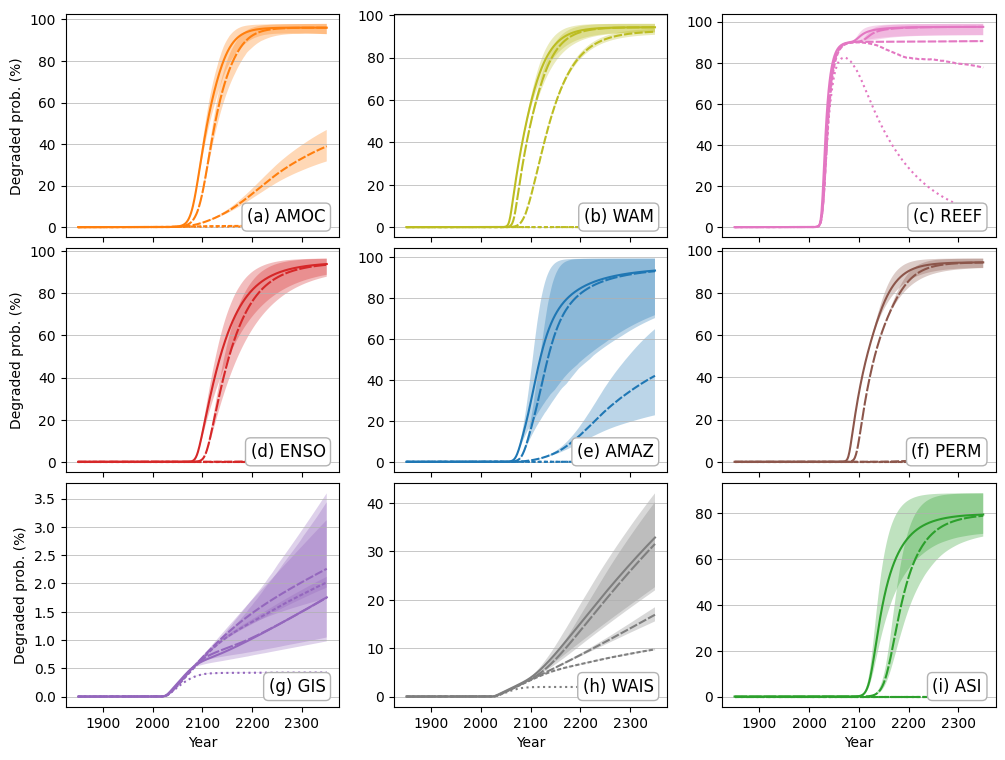

In [29]:
fig,axs = TE_3x3_fig(TE_ordered=TE_ordered)
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
TE_ind = {te:i for i,te in enumerate(TEs)}
years = np.arange(1850, 2351) 
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    for j in range(len(scenarios)):
        ribbon_plot(axs[i_ax//3,i_ax%3], years, D[j,:,i,:]*100, color=colors[i])
        axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
                                 c=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)

# Testing scripts

In [1]:
import matplotlib.pyplot as plt
import sys
sys.path.insert(1, '../')
import util

In [2]:
%run "../scripts/Simulations_equilibrium_solutions.py"

In [4]:
TEs = df_TEs.index.to_numpy()

NameError: name 'df_TEs' is not defined

In [3]:
D_theory.shape

(500, 10000, 9)

## Plotting 1.6C violin plots

Text(0.5, 0, 'Tipping element')

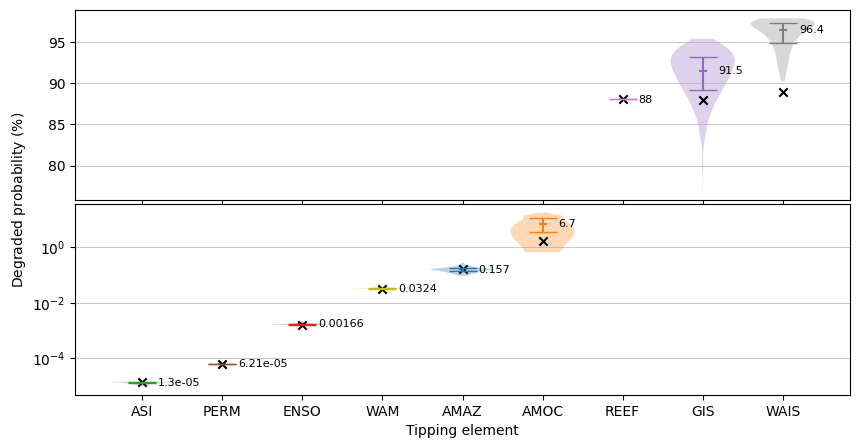

In [15]:
fig,axs = plt.subplots(2,1,sharex=True,figsize=(10,5))
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']

fig.subplots_adjust(hspace=0.02)

D_16 = D_theory[:,1600,:]
D_16_noint = D_theory_noint[1600,:]
y= np.median(D_16,axis=0)*100
yerr = np.abs(np.quantile(D_16*100,[0.25,0.75],axis=0)-y)
full = sorted(zip(list(y),TEs,range(9)))

# ax.set_yscale('log')
for i in range(9):
    i_ax=full[i][2]
    ax_num = int(i<=5)
    vp=axs[ax_num].violinplot(D_16[:,i_ax]*100,positions=[i+1],showmeans=False, showmedians=False,
        showextrema=False, widths=0.8)
    for b in vp['bodies']:
        b.set_facecolor(colors[i_ax])
    axs[ax_num].scatter([i+1],y[i_ax],color=util.plot.lighten_color(colors[i_ax],1),marker='_')
    axs[ax_num].errorbar([i+1],y[i_ax],yerr=yerr[:,i_ax].reshape(2,1),ls='',ecolor=util.plot.lighten_color(colors[i_ax],1),
                marker='',barsabove=True,capsize=10)
    # if i > 1:
    axs[ax_num].annotate('%.3g'%(y[i_ax]),[i+1.2,y[i_ax]],ha='left',va='center',fontsize=8)

axs[1].set_yscale('log')
ylim0 = axs[0].get_ylim()
ylim1 = axs[1].get_ylim()

axs[0].scatter(np.arange(1,10),[100*D_16_noint[i] for _,_,i in full],marker='x',color='k')
axs[1].scatter(np.arange(1,10),[100*D_16_noint[i] for _,_,i in full],marker='x',color='k')

axs[0].set_ylim(ylim0)
axs[1].set_ylim(ylim1)

axs[0].grid(visible=True,lw=0.5,axis='y')
axs[1].grid(visible=True,lw=0.5,axis='y')
# hide the spines between ax and ax2
# axs[0].spines.bottom.set_visible(False)
# axs[1].spines.top.set_visible(False)
axs[0].set_xticks([])  # don't put tick labels at the top
axs[1].xaxis.tick_bottom()

plt.xticks(np.arange(1,10), [te for _,te,_ in full]);
fig.text(0.06, 0.5, r"Degraded probability ($\%$)", va='center', rotation='vertical')
axs[1].set_xlabel("Tipping element")

# fig.savefig("../Figures/TE (sigmoid)/rx10c/GMSTs_1_6.pdf",format='pdf',bbox_inches='tight',dpi=300)

## Plotting individual TEs

In [2]:
from util.plot import lighten_color
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import util

NameError: name 'T_lim' is not defined

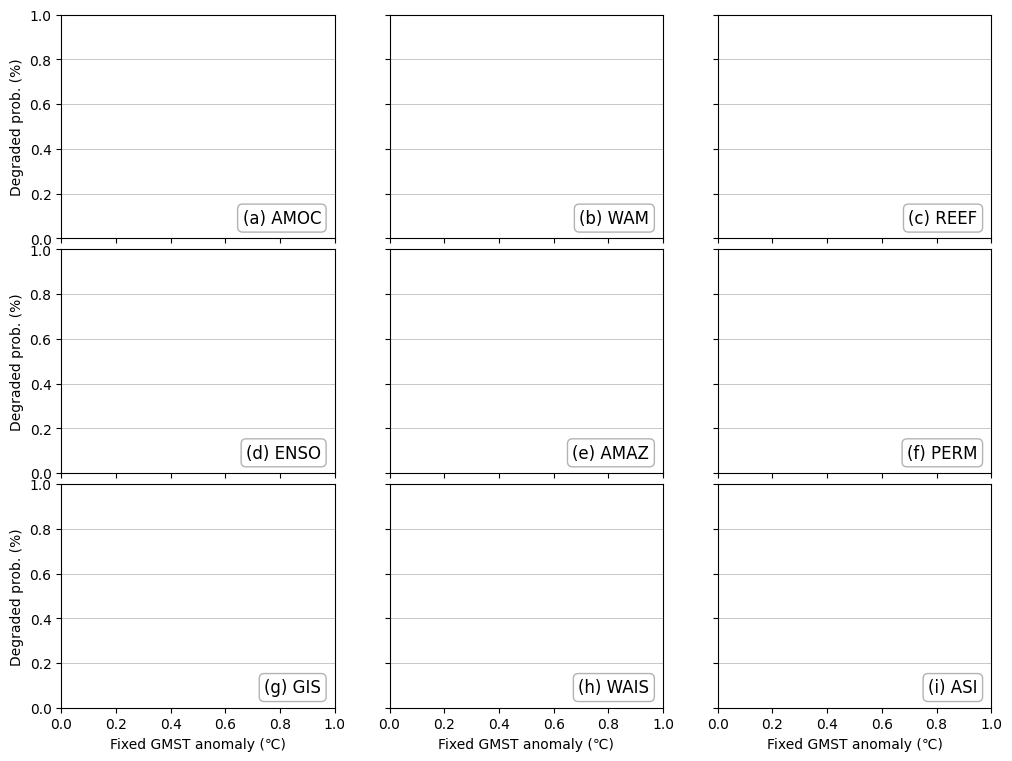

In [9]:
T = np.arange(0,10,step=0.001)
fig,axs = util.plot.TE_3x3_fig(xlabel= 'Fixed GMST anomaly (℃)',sharey=True)
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
TEs = df_TEs.index.to_numpy()
TE_ind = {te:i for i,te in enumerate(TEs)}
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
T_min = df_TEs['Threshold (°C) – Min.'].to_numpy()
T_max = df_TEs['Threshold (°C) – Max.'].to_numpy()
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].plot([T_lim[i]]*2,[0,100],c=lighten_color(colors[i],1.35),ls=':',lw=1)
    axs[i_ax//3,i_ax%3].plot([T_min[i]]*2,[0,100],c=lighten_color(colors[i],1.35),ls=':',lw=1)
    axs[i_ax//3,i_ax%3].plot([T_max[i]]*2,[0,100],c=lighten_color(colors[i],1.35),ls=':',lw=1)

    util.plot.ribbon_plot(axs[i_ax//3,i_ax%3], T, D_theory[:,:,i]*100, 
                          quantiles = [0.05,0.25], color=colors[i], shade=[0.3,0.65],alpha=[1,1],label=['']*2)
    axs[i_ax//3,i_ax%3].plot(T,D_theory[:,:,i].mean(axis=0)*100,
                             c=lighten_color(colors[i],1.35), 
                             ls='-',lw=1)

    axs[i_ax//3,i_ax%3].plot(T,D_theory_noint[:,i]*100,
                             c=lighten_color(colors[i],1.35), 
                             ls='--',lw=1)

lines=[
    Line2D([0], [0], color='k', lw=2, label='Sans interactions',ls='--'),
    Line2D([0], [0], color='k', lw=2, label='Mean'),
    Patch(facecolor=lighten_color('k',0.3), 
          edgecolor=lighten_color('k',0.3), label='$(P_5,P_{95})$'),
    Patch(facecolor=lighten_color('k',0.65), 
          edgecolor=lighten_color('k',0.65), label='$(P_{25},P_{75})$'),
    Line2D([0], [0], color='k', lw=2, label='Threshold',ls=':')] 
fig.legend(handles=lines,ncols=6,loc='upper center',prop={'size':12},borderaxespad=2)
axs[0,0].set_xlim([0,10])

# fig.savefig("../../Figures/GMSTs.pdf",format='pdf',bbox_inches='tight',dpi=300)

## Plotting at the Earth system level

In [21]:
ES_mean = D_theory.mean(axis=0).sum(axis=-1)
ES_5 = np.quantile(D_theory.sum(axis=-1),0.05,axis=0)
ES_25= np.quantile(D_theory.sum(axis=-1),0.25,axis=0)
ES_75= np.quantile(D_theory.sum(axis=-1),0.75,axis=0)
ES_95= np.quantile(D_theory.sum(axis=-1),0.95,axis=0)
ES_noint = D_theory_noint.sum(axis=-1)

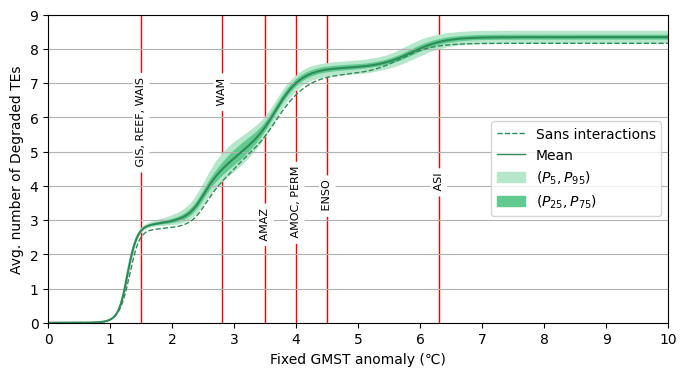

In [23]:
# fig,ax = plt.subplots(figsize=(8,5))
fig,ax = plt.subplots(figsize=(8,4))
theme_col = 'seagreen'
ax.grid(axis='y')

ax.plot(T,ES_noint,
        c=lighten_color(theme_col,1), 
        ls='--',lw=1,label='Sans interactions')
ax.plot(T,ES_mean,
        color=lighten_color(theme_col,1),label='Mean')
util.plot.ribbon_plot(ax, T, D_theory.sum(axis=-1), 
                      quantiles = [0.05,0.25], color='seagreen', shade=[0.3,0.65],alpha=[1,1],axis=0,label=['']*2)

T_lim_unique = np.sort(df_TEs['Threshold (°C) – Est.'].unique())
TEs_by_tlim = {t: df_TEs[df_TEs['Threshold (°C) – Est.']==t].index.to_list() for t in T_lim_unique}
for t in T_lim_unique:
    if ES_mean[np.argmin(np.abs(T-t))]<4.5:
        locs = (t,(ES_mean[np.argmin(np.abs(T-t))]+9)/2)
    else:
        locs = (t,ES_mean[np.argmin(np.abs(T-t))]/2)
    ax.plot([t]*2,[0,9],ls='-',c='r',zorder=0,lw=1)
    ax.annotate(' ' + ', '.join(TEs_by_tlim[t]), locs,
                ha='center',
                va='center',
                fontsize=8,
                bbox=dict(fc='white',edgecolor='none',boxstyle='round'),rotation=90)

ax.set_xticks(np.arange(11))
ax.set_ylim([0,9])
ax.set_xlim([0,10])
ax.set_ylabel('Avg. number of Degraded TEs')
ax.set_xlabel('Fixed GMST anomaly (℃)')

lines=[
    Line2D([0], [0], color='seagreen', lw=1, label='Sans interactions',ls='--'),
    Line2D([0], [0], color='seagreen', lw=1, label='Mean'),
    Patch(facecolor=lighten_color('seagreen',0.3), 
          edgecolor=lighten_color('seagreen',0.3), label='$(P_5,P_{95})$'),
    Patch(facecolor=lighten_color('seagreen',0.65), 
          edgecolor=lighten_color('seagreen',0.65), label='$(P_{25},P_{75})$')] 
legend=plt.legend(handles=lines,loc='center right')

fig.savefig("../../Figures/GMSTs_ES.pdf",format='pdf',bbox_inches='tight',dpi=300)

## plotting difference between interaction and sans interaction

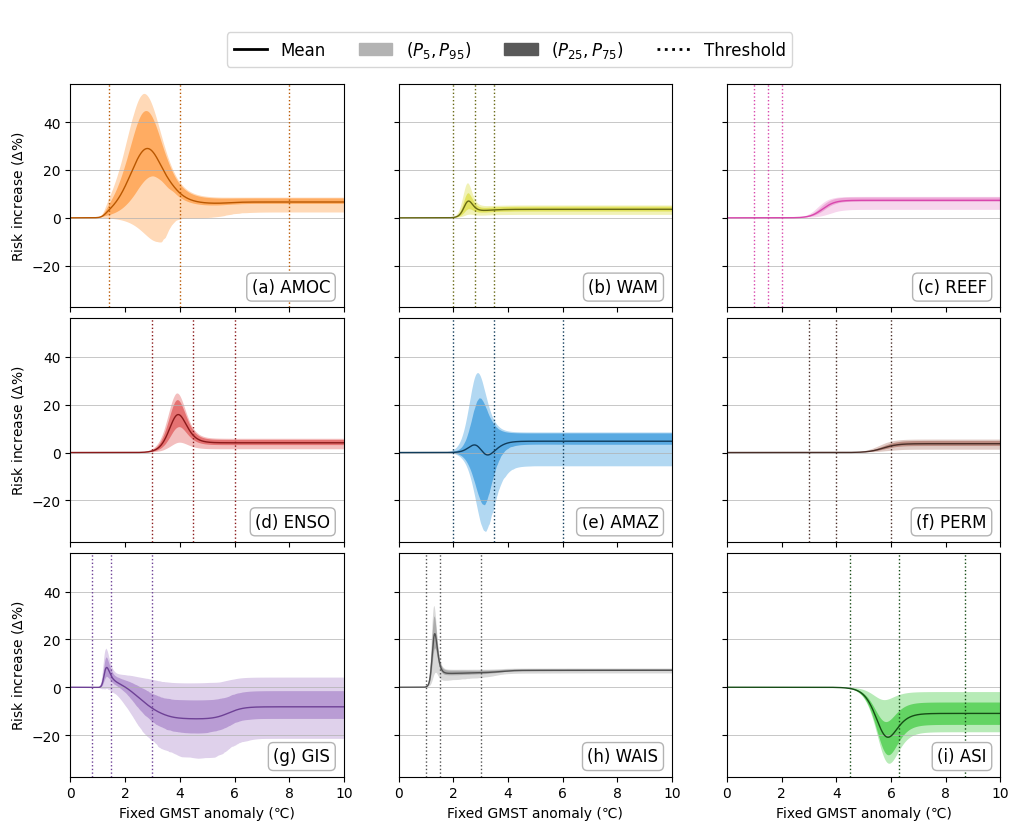

In [25]:
T = np.arange(0,10,step=0.001)
fig,axs = util.plot.TE_3x3_fig(xlabel= 'Fixed GMST anomaly (℃)',sharey=True)
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
TE_ind = {te:i for i,te in enumerate(TEs)}
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
T_min = df_TEs['Threshold (°C) – Min.'].to_numpy()
T_max = df_TEs['Threshold (°C) – Max.'].to_numpy()
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    util.plot.ribbon_plot(axs[i_ax//3,i_ax%3], T, 
                          (D_theory[:,:,i]-D_theory_noint[:,i])*100, 
                          quantiles = [0.05,0.25], color=colors[i], 
                          shade=[0.3,0.65],alpha=[1,1],label=['']*2)
    axs[i_ax//3,i_ax%3].plot(T,(D_theory[:,:,i].mean(axis=0)-D_theory_noint[:,i])*100,
                             c=lighten_color(colors[i],1.35), 
                             ls='-',lw=1)

ylim=axs[0,0].get_ylim()
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].plot([T_lim[i]]*2,ylim,c=lighten_color(colors[i],1.35),ls=':',lw=1)
    axs[i_ax//3,i_ax%3].plot([T_min[i]]*2,ylim,c=lighten_color(colors[i],1.35),ls=':',lw=1)
    axs[i_ax//3,i_ax%3].plot([T_max[i]]*2,ylim,c=lighten_color(colors[i],1.35),ls=':',lw=1)

lines=[
       Line2D([0], [0], color='k', lw=2, label='Mean'),
       Patch(facecolor=lighten_color('k',0.3), 
             edgecolor=lighten_color('k',0.3), label='$(P_5,P_{95})$'),
       Patch(facecolor=lighten_color('k',0.65), 
             edgecolor=lighten_color('k',0.65), label='$(P_{25},P_{75})$'),
    Line2D([0], [0], color='k', lw=2, label='Threshold',ls=':')] 
for i in range(3):
    axs[-1,i].set_xlabel('Fixed GMST anomaly (℃)')
    axs[i,0].set_ylabel(r'Risk increase ($\Delta \%$)')
    
axs[0,0].set_xlim([0,10])
axs[0,0].set_ylim(ylim)
# axs[0,0].set_ylim([0,100])

fig.legend(handles=lines,ncols=6,loc='upper center',prop={'size':12},borderaxespad=2)
fig.savefig("../../Figures/GMSTs_int_diff_abs.pdf",format='pdf',bbox_inches='tight',dpi=300)

In [7]:
# --------- READING DATA --------------
# Reading data about individual tipping elements:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0)
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
p_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Reading extended SSP temperatures
years = np.arange(1850, 2351) x
no_years = len(years)
df = pd.read_excel('../../Data/extendedSSPs.xlsx')
scenarios = df['scenario'].unique()
dfs = {s: df[df['scenario']==s].set_index('quantile').iloc[:,9:].transpose() for s in scenarios}

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

# -------- SIMULATIONS --------------
# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *= q_c
for t in range(no_years):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= util.dynamics.temp_response(dfs[s]['mean'].to_numpy()[t], T_lim, betas)